Selective Search is not ready. Upgrading OpenCV package...
Installation complete! Please click 'Runtime' -> 'Restart Session' in the top menu, then run this cell again.
553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Saving img2.jpg to img2.jpg
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


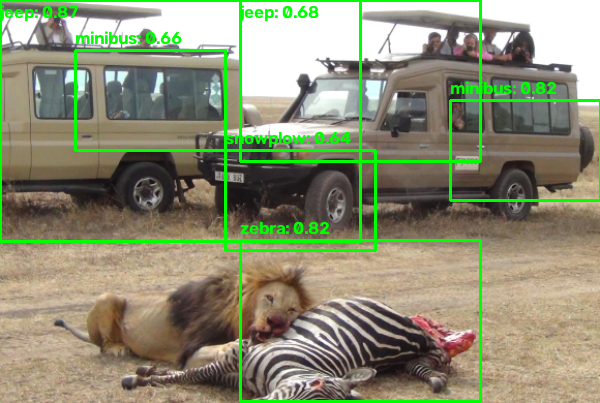

In [1]:
# ------------------------------------------------------------
# 0. SETUP (run once) - install OpenCV with Selective Search if needed.
# ------------------------------------------------------------

import os
import sys
import subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(
        cv2.ximgproc, "segmentation"
    )
except Exception:
    ss_ready = False

if not ss_ready:
    print("Selective Search is not ready. Upgrading OpenCV package...")
    subprocess.run(
        ["pip", "uninstall", "-y", "opencv-python",
         "opencv-python-headless", "opencv-contrib-python",
         "opencv-contrib-python-headless"],
        capture_output=True
    )
    subprocess.run(
        ["pip", "install", "-q", "opencv-contrib-python-headless"],
        capture_output=True
    )
    print("Installation complete! Please click 'Runtime' -> 'Restart Session' in the top menu, then run this cell again.")

# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    preprocess_input, decode_predictions
)
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow


# ------------------------------------------------------------
# 2. CLASSIFIER: VGG16 pre-trained on ImageNet (1000 classes; no training)
# Include top=True keeps VGG16's 1000-class head,
# so it can NAME each region directly.
# ------------------------------------------------------------

model = VGG16(weights="imagenet", include_top=True)


# ------------------------------------------------------------
# 3. REGION PROPOSALS: Selective Search (Fast), with a safe fallback
# ------------------------------------------------------------

def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()  # Fast mode

        boxes = [
            (x, y, w, h)
            for (x, y, w, h) in ss.process()
            if w > 40 and h > 40
        ]

        if boxes:
            return boxes[:max_regions]

    except Exception:
        pass

    # Fallback: multi-scale sliding windows (always works)
    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W * s), int(H * s)

        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]


# ------------------------------------------------------------
# 4. NON-MAXIMUM SUPPRESSION: drop duplicate overlapping boxes
# ------------------------------------------------------------

def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array(
        [[x, y, x + w, y + h] for (x, y, w, h, _, _) in dets],
        dtype=float
    )

    scores = np.array([d[5] for d in dets])
    order = scores.argsort()[::-1]
    keep = []

    while len(order):
        i = order[0]
        keep.append(i)
        rest = order[1:]

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        area_i = (
            (boxes[i, 2] - boxes[i, 0]) *
            (boxes[i, 3] - boxes[i, 1])
        )

        area_r = (
            (boxes[rest, 2] - boxes[rest, 0]) *
            (boxes[rest, 3] - boxes[rest, 1])
        )

        iou = inter / (area_i + area_r - inter + 1e-9)
        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]


# ------------------------------------------------------------
# 5. RUN IT: upload, downscale, propose, classify (batched), draw
# ------------------------------------------------------------

# Only continue if the libraries are properly set up
if not ss_ready and 'cv2' not in sys.modules:
    print("Please restart the session first to apply package updates.")
else:
    uploaded = files.upload()
    if not uploaded:
        print("No file uploaded.")
    else:
        image_path = next(iter(uploaded))
        img = cv2.imread(image_path)
        if img is None:
            print("Could not read the uploaded image.")
        else:
            H0, W0 = img.shape[:2]
            # Safe downscaling to avoid huge images overloading RAM
            img = cv2.resize(img, (600, int(H0 * 600.0 / W0)))

            # Cap proposed regions to 50 to absolutely ensure no memory issues
            boxes = get_region_proposals(img, max_regions=50)

            if not boxes:
                print("No region proposals generated.")
                cv2_imshow(img)
            else:
                # Process crops with validation to prevent shape mismatch or resize errors
                valid_crops = []
                valid_boxes = []
                for (x, y, w, h) in boxes:
                    crop = img[y:y+h, x:x+w]
                    if crop.size > 0:
                        valid_crops.append(cv2.resize(crop, (224, 224)))
                        valid_boxes.append((x, y, w, h))

                if not valid_crops:
                    print("No valid image crops could be created.")
                    cv2_imshow(img)
                else:
                    try:
                        crops_arr = np.array(valid_crops, dtype=np.float32)
                        preds = model.predict(
                            preprocess_input(crops_arr),
                            batch_size=16,
                            verbose=0
                        )

                        detections = []
                        CONFIDENCE_THRESHOLD = 0.50

                        for (x, y, w, h), p in zip(valid_boxes, preds):
                            _, label, prob = decode_predictions(p[None], top=1)[0][0]
                            if prob > CONFIDENCE_THRESHOLD:
                                detections.append((x, y, w, h, label, float(prob)))

                        if not detections:
                            print(f"No objects detected with confidence > {CONFIDENCE_THRESHOLD:.2f}.")
                        else:
                            detections = non_max_suppression(detections, iou_thr=0.3)

                            for (x, y, w, h, label, score) in detections:
                                cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
                                cv2.putText(
                                    img,
                                    f"{label}: {score:.2f}",
                                    (x, max(18, y - 6)),
                                    cv2.FONT_HERSHEY_SIMPLEX,
                                    0.6,
                                    (0, 255, 0),
                                    2
                                )
                    except Exception as e:
                        print(f"An error occurred during classification: {e}")

                    cv2_imshow(img)